# CQITE vs. Penz--van Leeuwen CITE

This notebook compares the constrained imaginary-time evolution of Penz--van Leeuwen with the CQITE implementation in the repository.

In [2]:
# ------------------------------------------------------------------
# Imports and repository discovery
# ------------------------------------------------------------------
import sys
from pathlib import Path

repo_candidates = [
    Path.cwd().parent,
    Path.cwd(),
    Path("/mnt/data/repo_full/ConstraintQuantumImaginary"),
]

for root in repo_candidates:
    if (root / "cqite").is_dir():
        sys.path.insert(0, str(root))
        REPO_ROOT = root
        break
else:
    raise RuntimeError(
        "CQITE repository not found. Put this notebook in the repository "
        "or adjust repo_candidates."
    )

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.optimize import differential_evolution
from qiskit.quantum_info import Statevector, SparsePauliOp

from cqite.engine.unitary_approximation import UnitaryApproximation
from cqite.engine.propagation import QITEPropagation
from cqite.engine.prepare_state import (
    constraint_rotation,
    density_from_rotations,
    support_only,
)
from cqite.simulation.backend import SimulatorBackend
from cqite.ansatz.commutator_basis import CommutatorBasis

print("Repository:", REPO_ROOT)


Repository: /Users/dacuomo/Documents/GitHub/ConstraintQuantumImaginary


In [3]:
# ------------------------------------------------------------------
# Plot style
# ------------------------------------------------------------------
# Explicitly chosen palette for a cleaner comparison.
COL_CITE = "#2F6B9A"      # muted blue
COL_CQITE = "#E07A2D"     # warm orange
COL_TARGET = "#6B4C9A"    # violet
COL_RESID = "#2A9D8F"     # teal
COL_LAMBDA = "#7A5195"    # purple
COL_PHASE = "#D1495B"     # red
COL_GRAY = "#5C677D"

plt.rcParams.update({
    "figure.figsize": (8.2, 5.0),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "grid.linestyle": "--",
})


In [4]:
# ------------------------------------------------------------------
# Benchmark parameters
# ------------------------------------------------------------------
nqubits = 3
nparticles = 2

dt = 1e-2
nsteps = 500

degree = 2
depth = 4
trot = 2

# External potential used ONLY to define the target density.
v_ext = np.array([2.0, 1.0, 0.0])

# Non-stationary point on the Penz--van Leeuwen fixed-density manifold.
phi_initial = np.array([np.pi / 2.0, 0.0])

tau = np.arange(nsteps + 1) * dt

print("dt =", dt)
print("nsteps =", nsteps)
print("total imaginary time =", tau[-1])


dt = 0.01
nsteps = 500
total imaginary time = 5.0


## 1. Triangle Hamiltonian and density constraints

In [6]:
# ------------------------------------------------------------------
# Hamiltonian
# ------------------------------------------------------------------
H = SparsePauliOp(
    ["III", "XXI", "YYI", "IXX", "IYY", "XZX", "YZY"],
    coeffs=[4.0, -0.5, -0.5, -0.5, -0.5, -0.5, -0.5],
)
Hm = H.to_matrix()

Z_ops = [
    SparsePauliOp(["ZII"], coeffs=[1.0]),
    SparsePauliOp(["IZI"], coeffs=[1.0]),
    SparsePauliOp(["IIZ"], coeffs=[1.0]),
]
Z_mats = [op.to_matrix() for op in Z_ops]

I8 = np.eye(8)
n_mats = [(I8 - Z) / 2 for Z in Z_mats]

# Independent constraints.
C = Z_ops[:2]
C_mats = [op.to_matrix() for op in C]

# N=2 computational-basis sector.
sector = [6, 5, 3]  # |110>, |101>, |011>
H_sector = Hm[np.ix_(sector, sector)]

print("H in the N=2 sector:")
print(np.real_if_close(H_sector))


H in the N=2 sector:
[[ 4. -1.  1.]
 [-1.  4. -1.]
 [ 1. -1.  4.]]


In [7]:
# ------------------------------------------------------------------
# Target density from H(v)
# ------------------------------------------------------------------
V_ext = sum(v_ext[j] * n_mats[j] for j in range(3))
H_v = Hm + V_ext

evals_v, evecs_v = np.linalg.eigh(H_v[np.ix_(sector, sector)])
psi_v_sector = evecs_v[:, 0]

rho_target = np.array([
    abs(psi_v_sector[0])**2 + abs(psi_v_sector[1])**2,
    abs(psi_v_sector[0])**2 + abs(psi_v_sector[2])**2,
    abs(psi_v_sector[1])**2 + abs(psi_v_sector[2])**2,
])

# Since n_j = (I-Z_j)/2, fixing rho fixes <Z>.
b = 1.0 - 2.0 * rho_target[:2]

print("Target density rho =", rho_target)
print("Sum rho =", rho_target.sum())
print("Target <Z_1>, <Z_2> =", b)
print("Ground-state energy of H(v) =", evals_v[0])


Target density rho = [0.21207688 0.81755801 0.97036511]
Sum rho = 1.9999999999999996
Target <Z_1>, <Z_2> = [ 0.57584625 -0.63511602]
Ground-state energy of H(v) = 4.324869129433353


## 2. Penz--van Leeuwen constrained-search minimum

For the two-particle triangle the fixed-density state is parametrized by two
phases. We minimize the corresponding energy over the full
\([0,2\pi)^2\) phase torus.

The resulting value is the static benchmark \(F(\rho)\) that both imaginary-time
methods should approach.


In [9]:
# ------------------------------------------------------------------
# Penz--van Leeuwen phase-space energy
# ------------------------------------------------------------------
def penz_energy(phi, rho):
    phi1, phi2 = phi
    a1 = np.sqrt((1-rho[0]) * (1-rho[2]))
    a2 = np.sqrt((1-rho[0]) * (1-rho[1]))
    a3 = np.sqrt((1-rho[1]) * (1-rho[2]))

    return 4.0 + 2.0 * (
        a1 * np.cos(phi1)
        - a2 * np.cos(phi2)
        - a3 * np.cos(phi1 - phi2)
    )

opt = differential_evolution(
    lambda x: penz_energy(x, rho_target),
    bounds=[(0, 2*np.pi), (0, 2*np.pi)],
    seed=1234,
    polish=True,
)

phi_opt = np.mod(opt.x, 2*np.pi)
E_penz = float(opt.fun)

print("Penz--van Leeuwen minimum")
print("  phi* =", phi_opt)
print("  F(rho) =", E_penz)


Penz--van Leeuwen minimum
  phi* = [3.14159297 0.        ]
  F(rho) = 3.083157368103487


In [10]:
# ------------------------------------------------------------------
# Common initial state
# ------------------------------------------------------------------
def penz_state_from_phases(rho, phi):
    phi1, phi2 = phi

    c1 = np.sqrt(1-rho[2]) * np.exp(1j * phi1)
    c2 = np.sqrt(1-rho[1]) * np.exp(1j * phi2)
    c3 = np.sqrt(1-rho[0])

    psi = np.zeros(8, dtype=complex)
    psi[6] = c1
    psi[5] = c2
    psi[3] = c3

    return psi / np.linalg.norm(psi)

psi0_data = penz_state_from_phases(rho_target, phi_initial)
psi0 = Statevector(psi0_data)

def observables(psi):
    E = np.real(np.vdot(psi, Hm @ psi))
    z = np.array([
        np.real(np.vdot(psi, Cmat @ psi))
        for Cmat in C_mats
    ])
    rho = np.array([
        np.real(np.vdot(psi, nmat @ psi))
        for nmat in n_mats
    ])
    return E, z, rho

E0, z0, rho0 = observables(psi0_data)

print("Initial phases =", phi_initial)
print("Initial energy =", E0)
print("Initial density =", rho0)
print("Target density =", rho_target)
print("Density residual =", np.linalg.norm(rho0-rho_target))
print("Initial <Z> =", z0)
print("Target <Z> =", b)
print("Particle number =", rho0.sum())


Initial phases = [1.57079633 0.        ]
Initial energy = 3.241711761329874
Initial density = [0.21207688 0.81755801 0.97036511]
Target density = [0.21207688 0.81755801 0.97036511]
Density residual = 3.510833468576701e-16
Initial <Z> = [ 0.57584625 -0.63511602]
Target <Z> = [ 0.57584625 -0.63511602]
Particle number = 2.0


In [11]:
# ------------------------------------------------------------------
# Initial-state stationarity diagnostic
# ------------------------------------------------------------------
def penz_gradient(phi, rho):
    phi1, phi2 = phi

    a1 = np.sqrt((1-rho[0]) * (1-rho[2]))
    a2 = np.sqrt((1-rho[0]) * (1-rho[1]))
    a3 = np.sqrt((1-rho[1]) * (1-rho[2]))

    return np.array([
        -2*a1*np.sin(phi1) + 2*a3*np.sin(phi1-phi2),
         2*a2*np.sin(phi2) - 2*a3*np.sin(phi1-phi2),
    ])

g0 = penz_gradient(phi_initial, rho_target)

print("Initial Penz gradient =", g0)
print("Gradient norm =", np.linalg.norm(g0))
print("Initial energy - F(rho) =", E0 - E_penz)


Initial Penz gradient = [-0.15855439 -0.14705982]
Gradient norm = 0.21625467742181104
Initial energy - F(rho) = 0.15855439322638665


## 3. Exact constrained imaginary-time evolution (CITE)

In [13]:
# ------------------------------------------------------------------
# Correct centered CITE multiplier equation
# ------------------------------------------------------------------
def cite_multipliers(psi, Hmat, Cmat_list):
    dim = Hmat.shape[0]
    identity = np.eye(dim)

    E = np.real(np.vdot(psi, Hmat @ psi))
    Cexp = np.array([
        np.real(np.vdot(psi, Cmat @ psi))
        for Cmat in Cmat_list
    ])

    dH = Hmat - E * identity
    dC = [
        Cmat - Cexp[i] * identity
        for i, Cmat in enumerate(Cmat_list)
    ]

    m = len(Cmat_list)
    M = np.empty((m, m), dtype=float)
    h = np.empty(m, dtype=float)

    for i in range(m):
        h[i] = np.real(
            np.vdot(psi, dC[i] @ dH @ psi)
        )

        for j in range(m):
            M[i, j] = np.real(
                np.vdot(psi, dC[i] @ dC[j] @ psi)
            )

    lam = -np.linalg.pinv(M, rcond=1e-12) @ h

    return lam, M, h


def cite_step(psi, Hmat, Cmat_list, dt):
    lam, M, h = cite_multipliers(
        psi, Hmat, Cmat_list
    )

    G = Hmat.copy()
    for lmb, Cmat in zip(lam, Cmat_list):
        G = G + lmb * Cmat

    psi_new = expm(-dt * G) @ psi
    psi_new /= np.linalg.norm(psi_new)

    return psi_new, lam, M, h


In [14]:
# ------------------------------------------------------------------
# Run exact CITE
# ------------------------------------------------------------------
cite_states = [psi0_data.copy()]
cite_energies = [E0]
cite_z = [z0]
cite_densities = [rho0]
cite_lambdas = [np.array([np.nan, np.nan])]
cite_cov_eigs = [np.linalg.eigvalsh(
    cite_multipliers(psi0_data, Hm, C_mats)[1]
)]

psi = psi0_data.copy()

for _ in range(nsteps):
    psi, lam, M, h = cite_step(
        psi, Hm, C_mats, dt
    )

    E, z, rho = observables(psi)

    cite_states.append(psi.copy())
    cite_energies.append(E)
    cite_z.append(z)
    cite_densities.append(rho)
    cite_lambdas.append(lam)
    cite_cov_eigs.append(np.linalg.eigvalsh(M))

cite_energies = np.asarray(cite_energies)
cite_z = np.asarray(cite_z)
cite_densities = np.asarray(cite_densities)
cite_lambdas = np.asarray(cite_lambdas)
cite_cov_eigs = np.asarray(cite_cov_eigs)

print("CITE final energy =", cite_energies[-1])
print("CITE final density =", cite_densities[-1])
print("CITE density residual =",
      np.linalg.norm(cite_densities[-1]-rho_target))
print("CITE final error vs F(rho) =",
      abs(cite_energies[-1]-E_penz))


CITE final energy = 3.082692306467146
CITE final density = [0.21179912 0.81858856 0.96961232]
CITE density residual = 0.0013060945232670612
CITE final error vs F(rho) = 0.0004650616363410798


## 4. CQITE using the repository pipeline

The CQITE implementation is not replaced by the CITE reference. We use the
repository's own construction:

```text
constraints + targets
        ↓
constraint_rotation
        ↓
density_from_rotations
        ↓
support_only
        ↓
CommutatorBasis.from_seed
        ↓
UnitaryApproximation
        ↓
QITEPropagation
```

The initial state is the same Penz--van Leeuwen phase-parametrized state used
for CITE.


In [16]:
# ------------------------------------------------------------------
# Build CQITE seed and commutator basis
# ------------------------------------------------------------------
rotations = [
    constraint_rotation(c, target)
    for c, target in zip(C, b)
]

rho_seed = density_from_rotations(
    nqubits,
    rotations,
    degree=degree,
)

seeds = support_only(rho_seed)

basis = CommutatorBasis.from_seed(
    hamiltonian=H,
    seeds=seeds,
    depth=depth,
)

print("\nNumber of seed operators:", len(seeds.paulis))
print("Number of pool operators:", len(basis.paulis))



Number of seed operators: 14
Number of pool operators: 38


In [17]:
# ------------------------------------------------------------------
# CQITE propagation
# ------------------------------------------------------------------
backend = SimulatorBackend()
approx = UnitaryApproximation(
    basis,
    trot=trot,
)
prop = QITEPropagation(
    H,
    C,
    backend,
    approx,
)

psi = psi0.copy()

cqite_states = [psi.data.copy()]
cqite_energies = [E0]
cqite_z = [z0]
cqite_densities = [rho0]

for _ in range(nsteps):
    _, psi = prop.step(
        None,
        psi,
        dt,
    )

    E, z, rho = observables(psi.data)

    cqite_states.append(psi.data.copy())
    cqite_energies.append(E)
    cqite_z.append(z)
    cqite_densities.append(rho)

cqite_energies = np.asarray(cqite_energies)
cqite_z = np.asarray(cqite_z)
cqite_densities = np.asarray(cqite_densities)

print("CQITE final energy =", cqite_energies[-1])
print("CQITE final density =", cqite_densities[-1])
print("CQITE density residual =",
      np.linalg.norm(cqite_densities[-1]-rho_target))
print("CQITE final error vs F(rho) =",
      abs(cqite_energies[-1]-E_penz))


CQITE final energy = 3.0818488293641773
CQITE final density = [0.21291205 0.81720512 0.96988283]
CQITE density residual = 0.0010269563435444378
CQITE final error vs F(rho) = 0.0013085387393099168


# 5. Main comparison


In [19]:
# ------------------------------------------------------------------
# Numerical summary
# ------------------------------------------------------------------
energy_gap = cqite_energies - cite_energies
cite_error = cite_energies - E_penz
cqite_error = cqite_energies - E_penz

cite_constraint_residual = np.linalg.norm(
    cite_z - b[None, :],
    axis=1,
)
cqite_constraint_residual = np.linalg.norm(
    cqite_z - b[None, :],
    axis=1,
)

cite_density_residual = np.linalg.norm(
    cite_densities - rho_target[None, :],
    axis=1,
)
cqite_density_residual = np.linalg.norm(
    cqite_densities - rho_target[None, :],
    axis=1,
)

print("============================================================")
print("FINAL COMPARISON")
print("============================================================")
print(f"Penz F(rho)          : {E_penz:.12f}")
print(f"CITE final energy    : {cite_energies[-1]:.12f}")
print(f"CQITE final energy   : {cqite_energies[-1]:.12f}")
print(f"CITE |E-F|           : {abs(cite_error[-1]):.6e}")
print(f"CQITE |E-F|          : {abs(cqite_error[-1]):.6e}")
print(f"|CQITE-CITE|         : {abs(energy_gap[-1]):.6e}")
print()
print(f"CITE max Z residual  : {cite_constraint_residual.max():.6e}")
print(f"CQITE max Z residual : {cqite_constraint_residual.max():.6e}")
print(f"CITE max rho residual: {cite_density_residual.max():.6e}")
print(f"CQITE max rho residual:{cqite_density_residual.max():.6e}")
print()
print(f"CITE final N         : {cite_densities[-1].sum():.12f}")
print(f"CQITE final N        : {cqite_densities[-1].sum():.12f}")


FINAL COMPARISON
Penz F(rho)          : 3.083157368103
CITE final energy    : 3.082692306467
CQITE final energy   : 3.081848829364
CITE |E-F|           : 4.650616e-04
CQITE |E-F|          : 1.308539e-03
|CQITE-CITE|         : 8.434771e-04

CITE max Z residual  : 2.134655e-03
CQITE max Z residual : 1.813332e-03
CITE max rho residual: 1.306095e-03
CQITE max rho residual:1.026956e-03

CITE final N         : 2.000000000000
CQITE final N        : 1.999999997112


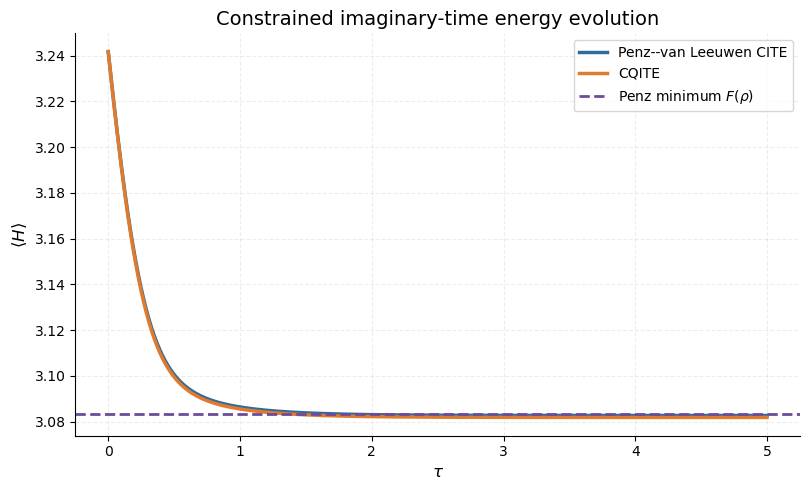

In [20]:
# ------------------------------------------------------------------
# Plot 1: Energy evolution
# ------------------------------------------------------------------
fig, ax = plt.subplots()

ax.plot(
    tau, cite_energies,
    color=COL_CITE,
    linewidth=2.5,
    label="Penz--van Leeuwen CITE",
)
ax.plot(
    tau, cqite_energies,
    color=COL_CQITE,
    linewidth=2.5,
    label="CQITE",
)
ax.axhline(
    E_penz,
    color=COL_TARGET,
    linestyle="--",
    linewidth=2.0,
    label=r"Penz minimum $F(\rho)$",
)

ax.set_xlabel(r"$\tau$")
ax.set_ylabel(r"$\langle H\rangle$")
ax.set_title("Constrained imaginary-time energy evolution")
ax.legend()
plt.tight_layout()
plt.show()


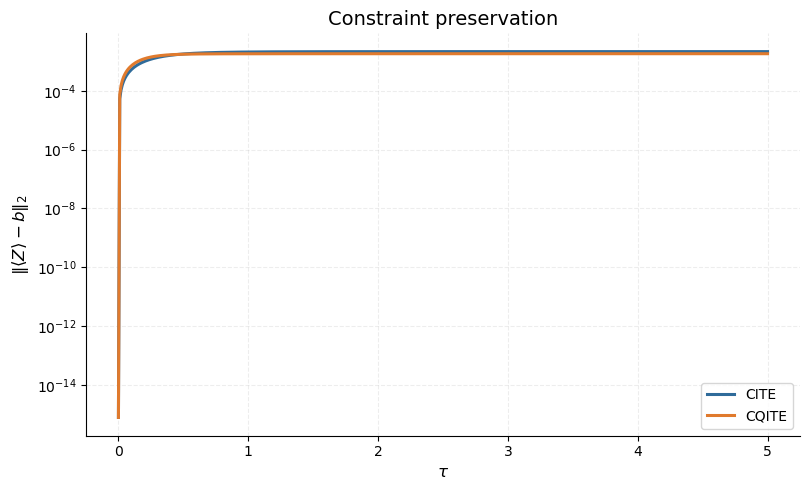

In [21]:
# ------------------------------------------------------------------
# Plot 4: Constraint preservation
# ------------------------------------------------------------------
fig, ax = plt.subplots()

ax.semilogy(
    tau,
    np.maximum(cite_constraint_residual, 1e-16),
    color=COL_CITE,
    linewidth=2.2,
    label="CITE",
)
ax.semilogy(
    tau,
    np.maximum(cqite_constraint_residual, 1e-16),
    color=COL_CQITE,
    linewidth=2.2,
    label="CQITE",
)

ax.set_xlabel(r"$\tau$")
ax.set_ylabel(r"$\|\langle Z\rangle-b\|_2$")
ax.set_title("Constraint preservation")
ax.legend()
plt.tight_layout()
plt.show()


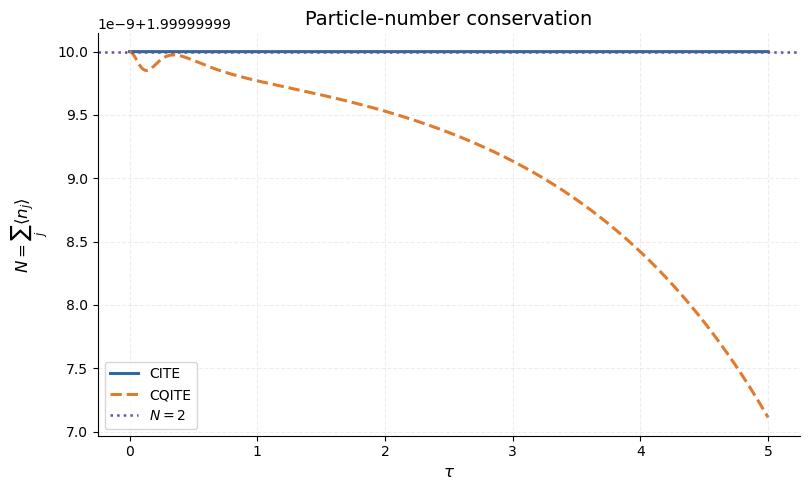

In [22]:
# ------------------------------------------------------------------
# Plot 9: Particle number
# ------------------------------------------------------------------
N_cite = cite_densities.sum(axis=1)
N_cqite = cqite_densities.sum(axis=1)

fig, ax = plt.subplots()

ax.plot(
    tau, N_cite,
    color=COL_CITE,
    linewidth=2.2,
    label="CITE",
)
ax.plot(
    tau, N_cqite,
    color=COL_CQITE,
    linewidth=2.2,
    linestyle="--",
    label="CQITE",
)
ax.axhline(
    nparticles,
    color=COL_TARGET,
    linestyle=":",
    linewidth=1.8,
    label=r"$N=2$",
)

ax.set_xlabel(r"$\tau$")
ax.set_ylabel(r"$N=\sum_j\langle n_j\rangle$")
ax.set_title("Particle-number conservation")
ax.legend()
plt.tight_layout()
plt.show()


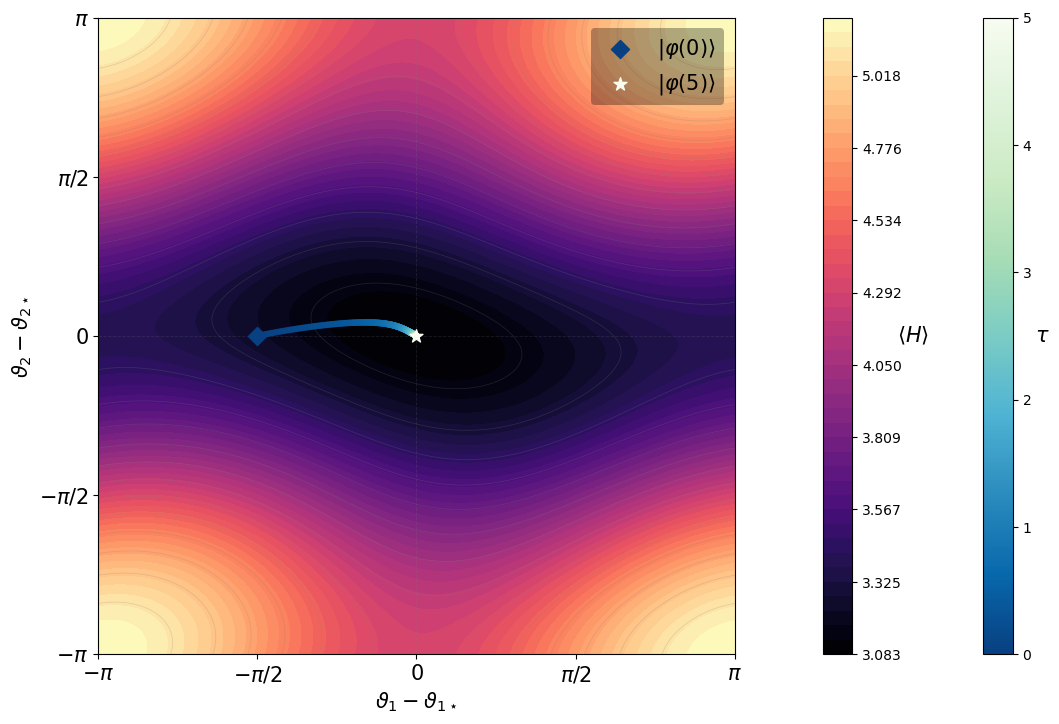

In [23]:
# ======================================================================
# CQITE evolution on the Penz--van Leeuwen constrained-search landscape
#
# The CQITE state is |phi(tau)>.
#
# The CQITE constraints are
#
#       <phi(tau)| C_j |phi(tau)> = b_j
#
# and the energy being minimized is
#
#       <phi(tau)| H |phi(tau)>.
#
# The Penz--van Leeuwen phases (phi_1, phi_2) are used ONLY as a
# visualization chart for the fixed-density manifold.
# ======================================================================


import numpy as np
import matplotlib.pyplot as plt

plt.rcdefaults()

# ----------------------------------------------------------------------
# 1. CQITE states and energies
# ----------------------------------------------------------------------

cqite_states = np.asarray(cqite_states)

tau = np.asarray(tau)

cqite_energy = np.asarray(cqite_energies)


# ----------------------------------------------------------------------
# 2. Constraint values
# ----------------------------------------------------------------------

cqite_z = np.asarray([
    [
        np.real(np.vdot(psi, Cmat @ psi))
        for Cmat in C_mats
    ]
    for psi in cqite_states
])

constraint_residual = cqite_z - b[None, :]

constraint_error = np.linalg.norm(
    constraint_residual,
    axis=1,
)


# ----------------------------------------------------------------------
# 3. Density values
# ----------------------------------------------------------------------

cqite_density = np.asarray([
    [
        np.real(np.vdot(psi, nmat @ psi))
        for nmat in n_mats
    ]
    for psi in cqite_states
])

density_error = np.linalg.norm(
    cqite_density - rho_target[None, :],
    axis=1,
)


# ----------------------------------------------------------------------
# 4. Penz phase coordinates
# ----------------------------------------------------------------------

def phases_from_state(psi):

    c1 = psi[6]
    c2 = psi[5]
    c3 = psi[3]

    gauge = np.exp(-1j * np.angle(c3))

    c1 = c1 * gauge
    c2 = c2 * gauge

    return np.mod(
        np.array([
            np.angle(c1),
            np.angle(c2),
        ]),
        2.0 * np.pi,
    )


cqite_phases = np.asarray([
    phases_from_state(psi)
    for psi in cqite_states
])


# ----------------------------------------------------------------------
# 5. Periodic coordinate transformation
# ----------------------------------------------------------------------

def wrap_phase(phi):
    return (phi + np.pi) % (2.0 * np.pi) - np.pi


def centered_phase(phi, reference):
    return wrap_phase(phi - reference)


cqite_chart = np.asarray([
    [
        centered_phase(phi[0], phi_opt[0]),
        centered_phase(phi[1], phi_opt[1]),
    ]
    for phi in cqite_phases
])


phi_initial_chart = np.array([
    centered_phase(phi_initial[0], phi_opt[0]),
    centered_phase(phi_initial[1], phi_opt[1]),
])


# ----------------------------------------------------------------------
# 6. Penz--van Leeuwen energy landscape
# ----------------------------------------------------------------------

ngrid = 220

x = np.linspace(
    -np.pi,
    np.pi,
    ngrid,
)

y = np.linspace(
    -np.pi,
    np.pi,
    ngrid,
)

X, Y = np.meshgrid(x, y)

E_landscape = np.empty_like(X)

for i in range(ngrid):
    for j in range(ngrid):

        phi1 = wrap_phase(
            X[i, j] + phi_opt[0]
        )

        phi2 = wrap_phase(
            Y[i, j] + phi_opt[1]
        )

        E_landscape[i, j] = penz_energy(
            (
                phi1 % (2.0 * np.pi),
                phi2 % (2.0 * np.pi),
            ),
            rho_target,
        )


# ----------------------------------------------------------------------
# 7. Relevant energies
# ----------------------------------------------------------------------

E_initial = float(cqite_energy[0])

E_final = float(cqite_energy[-1])

E_constrained = float(E_penz)

E0_H = 3.0


# ----------------------------------------------------------------------
# 8. Figure
# ----------------------------------------------------------------------

fig = plt.figure(
    figsize=(10.5, 7.4)
)


# ----------------------------------------------------------------------
# Figure layout
#
# Main plot | gap | energy colorbar | larger gap | time colorbar
#
# The larger gap before the second colorbar prevents the colorbars from
# appearing too close to the main plot.
# ----------------------------------------------------------------------

gs = fig.add_gridspec(
    nrows=1,
    ncols=5,
    width_ratios=[
        1.0,
        0.12,
        0.045,
        0.20,
        0.045,
    ],
    left=0.08,
    right=0.96,
    bottom=0.10,
    top=0.96,
    wspace=0.0,
)


ax = fig.add_subplot(
    gs[0, 0],
)

cax_energy = fig.add_subplot(
    gs[0, 2],
)

cax_time = fig.add_subplot(
    gs[0, 4],
)


# ----------------------------------------------------------------------
# Energy landscape
# ----------------------------------------------------------------------

levels = np.linspace(
    E_landscape.min(),
    E_landscape.max(),
    45,
)

energy_map = ax.contourf(
    X,
    Y,
    E_landscape,
    levels=levels,
    cmap="magma",
)


# Energy contours
ax.contour(
    X,
    Y,
    E_landscape,
    levels=16,
    colors="grey",
    linewidths=0.55,
    alpha=0.23,
)


# ----------------------------------------------------------------------
# Energy colorbar
# ----------------------------------------------------------------------

energy_bar = fig.colorbar(
    energy_map,
    cax=cax_energy,
)

energy_bar.set_label(
    r"$\langle H\rangle$",
    fontsize=15,
    labelpad=8,
    rotation=0,
    va="center"
)


# ----------------------------------------------------------------------
# CQITE states coloured by imaginary time
# ----------------------------------------------------------------------

time_map = ax.scatter(
    cqite_chart[:, 0],
    cqite_chart[:, 1],
    c=tau,
    cmap="GnBu_r",
    s=22,
    alpha=1.0,
    edgecolors="none",
    zorder=5,
)


# ----------------------------------------------------------------------
# Imaginary-time colorbar
# ----------------------------------------------------------------------

time_bar = fig.colorbar(
    time_map,
    cax=cax_time,
)

time_bar.set_label(
    r"$\tau$",
    fontsize=15,
    labelpad=8,
    rotation=0,
    va="center"
)


# ----------------------------------------------------------------------
# Direction arrows
# ----------------------------------------------------------------------

n_arrows = 7

arrow_indices = np.linspace(
    0,
    len(cqite_chart) - 2,
    n_arrows,
    dtype=int,
)

for k in arrow_indices:

    step = max(
        1,
        len(cqite_chart) // 30,
    )

    k2 = min(
        k + step,
        len(cqite_chart) - 1,
    )

    dx = (
        cqite_chart[k2, 0]
        - cqite_chart[k, 0]
    )

    dy = (
        cqite_chart[k2, 1]
        - cqite_chart[k, 1]
    )

    if abs(dx) > np.pi or abs(dy) > np.pi:
        continue


# ----------------------------------------------------------------------
# Initial CQITE state
# ----------------------------------------------------------------------

ax.scatter(
    phi_initial_chart[0],
    phi_initial_chart[1],
    s=85,
    marker="D",
    color=plt.get_cmap("GnBu_r")(0.0),
    linewidth=1.0,
    zorder=9.,
    label=(
        rf"$|\varphi(0)\rangle$"
    ),
)


# ----------------------------------------------------------------------
# Final CQITE state
# ----------------------------------------------------------------------

ax.scatter(
    cqite_chart[-1, 0],
    cqite_chart[-1, 1],
    s=95,
    marker="*",
    color=plt.get_cmap("GnBu_r")(1.0),
    linewidth=1.0,
    zorder=9.,
    label=(
        rf"$|\varphi(5)\rangle$"
    ),
)


# ----------------------------------------------------------------------
# Constrained minimum crosshair
# ----------------------------------------------------------------------

ax.axhline(
    0.0,
    color="grey",
    linewidth=0.65,
    linestyle="--",
    alpha=0.18,
    zorder=2,
)

ax.axvline(
    0.0,
    color="grey",
    linewidth=0.65,
    linestyle="--",
    alpha=0.18,
    zorder=2,
)


# ----------------------------------------------------------------------
# CQITE constraint diagnostic
# ----------------------------------------------------------------------

max_constraint_error = float(
    np.max(constraint_error)
)

max_density_error = float(
    np.max(density_error)
)


# ----------------------------------------------------------------------
# Periodic centred coordinates
# ----------------------------------------------------------------------

ax.set_xlim(
    -np.pi,
    np.pi,
)

ax.set_ylim(
    -np.pi,
    np.pi,
)


# ----------------------------------------------------------------------
# Equal physical scale
# ----------------------------------------------------------------------

ax.set_aspect(
    "equal",
    adjustable="box",
)


# ----------------------------------------------------------------------
# Ticks
# ----------------------------------------------------------------------

ticks = [
    -np.pi,
    -np.pi / 2,
    0.0,
    np.pi / 2,
    np.pi,
]

tick_labels = [
    r"$-\pi$",
    r"$-\pi/2$",
    r"$0$",
    r"$\pi/2$",
    r"$\pi$",
]

ax.set_xticks(ticks)
ax.set_xticklabels(tick_labels)

ax.set_yticks(ticks)
ax.set_yticklabels(tick_labels)

ax.tick_params(
    axis="both",
    labelsize=15,
)


# ----------------------------------------------------------------------
# Axes labels
# ----------------------------------------------------------------------

ax.set_xlabel(
    r"$\vartheta_1-\vartheta_{1\star}$",
    fontsize=15,
)
ax.set_ylabel(
    r"$\vartheta_2-\vartheta_{2\star}$",
    fontsize=15,
)

# ----------------------------------------------------------------------
# Legend
# ----------------------------------------------------------------------

leg = ax.legend(
    loc="upper right",
    framealpha=0.3,
    fontsize=15,
)
frame = leg.get_frame()
frame.set_facecolor("black")
frame.set_edgecolor("none")

for text in leg.get_texts():
    text.set_color("black")


# ----------------------------------------------------------------------
# Save and display
# ----------------------------------------------------------------------

plt.savefig(
    "cqite_penz_landscape.pdf",
    bbox_inches="tight",
)

plt.show()